## Extracao dos dados

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import numpy as np
import seaborn as sns
from scipy import stats
import json
import subprocess
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, roc_curve, roc_auc_score
)
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

pd.set_option("display.max_columns", None)

dataframe_de_churn_inicial = pd.read_csv("C:\\Projetos\\FIAP\\Fase_1\\Tech_Challenge_Churn_Prediction\\data\\raw\\Telco-Customer-Churn.csv", sep=",")

dataframe_de_churn_inicial.head(n=100)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,Yes
96,9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,No
97,0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,Yes
98,3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,No


## Transformacao de nomes de features para portugues

In [2]:
colunas_pt_br = {
    "customerID": "id_cliente",
    "gender": "genero",
    "SeniorCitizen": "cliente_em_idade_avancada",
    "Partner": "casado",
    "Dependents": "dependentes",
    "tenure": "meses_como_cliente",
    "PhoneService": "possui_servico_telefonico",
    "MultipleLines": "possui_multiplas_linhas",
    "InternetService": "possui_servico_de_internet",
    "OnlineSecurity": "possui_seguranca_online",
    "OnlineBackup": "possui_backup_online",
    "DeviceProtection": "possui_protecao_dispositivo",
    "TechSupport": "possui_suporte_tecnico_premium",
    "StreamingTV": "possui_streaming_tv_terceiros",
    "StreamingMovies": "possui_streaming_filmes_terceiros",
    "Contract": "tipo_contrato",
    "PaperlessBilling": "fatura_sem_papel",
    "PaymentMethod": "metodo_pagamento",
    "MonthlyCharges": "cobranca_mensal",
    "TotalCharges": "total_cobrado_durante_trimestre",
    "Churn": "target",
}

dataframe_de_churn_inicial_colunas_traduzidas = dataframe_de_churn_inicial.rename(columns=colunas_pt_br)

dataframe_de_churn_inicial_colunas_traduzidas.head(n=100)

,id_cliente,genero,cliente_em_idade_avancada,casado,dependentes,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,Yes
96,9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,No
97,0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,Yes
98,3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,No


## Mudanca da variavel target para binaria

In [3]:
dataframe_de_churn_inicial_colunas_traduzidas["target"] = dataframe_de_churn_inicial_colunas_traduzidas["target"].map({"Yes": 1, "No": 0})

dataframe_de_churn_inicial_colunas_traduzidas.head(n=100)

,id_cliente,genero,cliente_em_idade_avancada,casado,dependentes,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,1
96,9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,0
97,0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,1
98,3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,0


## Removendo features sensiveis

In [4]:
colunas_sensiveis_sem_relevancia_para_churn = ["id_cliente", "genero", "dependentes"]

dataframe_de_churn_inicial_colunas_sensiveis_removidas = dataframe_de_churn_inicial_colunas_traduzidas.drop(columns=colunas_sensiveis_sem_relevancia_para_churn)

dataframe_de_churn_inicial_colunas_sensiveis_removidas.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,0,Yes,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,0,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,0,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,0,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,0,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,1
96,0,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,0
97,0,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,1
98,0,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,0


## Binarizando features categoricas deterministicas

In [5]:
dataframe_de_churn_inicial_colunas_sensiveis_removidas["casado"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["casado"].map({"Yes": 1, "No": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["fatura_sem_papel"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["fatura_sem_papel"].map({"Yes": 1, "No": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_servico_telefonico"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_servico_telefonico"].map({"Yes": 1, "No": 0})

dataframe_de_churn_inicial_colunas_sensiveis_removidas.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,0,1,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.5,0
2,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,1,Electronic check,78.95,927.35,1
96,0,1,71,1,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,1,Credit card (automatic),66.85,4748.7,0
97,0,0,5,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,0,Mailed check,21.05,113.85,1
98,0,0,52,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,0,Bank transfer (automatic),21.00,1107.2,0


## Trabalhando com features binarias nao determinitiscas

In [6]:
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_seguranca_online"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_seguranca_online"].map({"Yes": 1, "No": 0, "No internet service": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_backup_online"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_backup_online"].map({"Yes": 1, "No": 0, "No internet service": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_protecao_dispositivo"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_protecao_dispositivo"].map({"Yes": 1, "No": 0, "No internet service": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_suporte_tecnico_premium"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_suporte_tecnico_premium"].map({"Yes": 1, "No": 0, "No internet service": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_streaming_tv_terceiros"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_streaming_tv_terceiros"].map({"Yes": 1, "No": 0, "No internet service": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_streaming_filmes_terceiros"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_streaming_filmes_terceiros"].map({"Yes": 1, "No": 0, "No internet service": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_multiplas_linhas"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_multiplas_linhas"].map({"Yes": 1, "No": 0, "No phone service": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["tipo_contrato"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["tipo_contrato"].map({"Month-to-month": 0, "One year": 1, "Two year": 2})

codigo_para_servico_de_internet = {"No": "sem_internet", "Fiber optic": "fibra_optica", "DSL": "dsl"}
servico_de_internet_dummies = pd.get_dummies(
    dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_servico_de_internet"].map(codigo_para_servico_de_internet),
    prefix="possui_servico_de_internet"
).astype(int)

codigo_para_metodo_pagamento = {"Mailed check": "mailed_check", "Electronic check": "electronic_check", "Bank transfer (automatic)": "bank_transfer_automatic", "Credit card (automatic)": "credit_card_automatic"}
metodo_pagamento_dummies = pd.get_dummies(
    dataframe_de_churn_inicial_colunas_sensiveis_removidas["metodo_pagamento"].map(codigo_para_metodo_pagamento),
    prefix="metodo_pagamento"
).astype(int)

dataframe_de_churn_inicial_colunas_sensiveis_removidas = pd.concat(
    [dataframe_de_churn_inicial_colunas_sensiveis_removidas.drop(columns=["possui_servico_de_internet", "metodo_pagamento"]), servico_de_internet_dummies, metodo_pagamento_dummies],
    axis=1
)

dataframe_de_churn_inicial_colunas_sensiveis_removidas.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_durante_trimestre,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,29.85,0,1,0,0,0,0,1,0
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,1889.5,0,1,0,0,0,0,0,1
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,108.15,1,1,0,0,0,0,0,1
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,1840.75,0,1,0,0,1,0,0,0
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,927.35,1,0,1,0,0,0,1,0
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,4748.7,0,1,0,0,0,1,0,0
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,113.85,1,0,0,1,0,0,0,1
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,1107.2,0,0,0,1,1,0,0,0


## Informacoes estruturais

In [7]:
dataframe_de_churn_inicial_colunas_sensiveis_removidas.info()
soma_de_registros_iniciais = dataframe_de_churn_inicial_colunas_sensiveis_removidas.shape[0]

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   cliente_em_idade_avancada                 7043 non-null   int64  
 1   casado                                    7043 non-null   int64  
 2   meses_como_cliente                        7043 non-null   int64  
 3   possui_servico_telefonico                 7043 non-null   int64  
 4   possui_multiplas_linhas                   7043 non-null   int64  
 5   possui_seguranca_online                   7043 non-null   int64  
 6   possui_backup_online                      7043 non-null   int64  
 7   possui_protecao_dispositivo               7043 non-null   int64  
 8   possui_suporte_tecnico_premium            7043 non-null   int64  
 9   possui_streaming_tv_terceiros             7043 non-null   int64  
 10  possui_streaming_filmes_terceiros         7043 

## Identificando Missing Values

In [8]:
print(dataframe_de_churn_inicial_colunas_sensiveis_removidas.isna().sum())
dataframe_validacao_cenario_meses_como_cliente_zero = dataframe_de_churn_inicial_colunas_sensiveis_removidas[
    (dataframe_de_churn_inicial_colunas_sensiveis_removidas["meses_como_cliente"].isna())
    | (dataframe_de_churn_inicial_colunas_sensiveis_removidas["meses_como_cliente"] == 0)]
dataframe_validacao_cenario_meses_como_cliente_zero.head(n=100)

cliente_em_idade_avancada                   0
casado                                      0
meses_como_cliente                          0
possui_servico_telefonico                   0
possui_multiplas_linhas                     0
possui_seguranca_online                     0
possui_backup_online                        0
possui_protecao_dispositivo                 0
possui_suporte_tecnico_premium              0
possui_streaming_tv_terceiros               0
possui_streaming_filmes_terceiros           0
tipo_contrato                               0
fatura_sem_papel                            0
cobranca_mensal                             0
total_cobrado_durante_trimestre             0
target                                      0
possui_servico_de_internet_dsl              0
possui_servico_de_internet_fibra_optica     0
possui_servico_de_internet_sem_internet     0
metodo_pagamento_bank_transfer_automatic    0
metodo_pagamento_credit_card_automatic      0
metodo_pagamento_electronic_check 

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_durante_trimestre,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
488,0,1,0,0,0,1,0,1,1,1,0,2,1,52.55,,0,1,0,0,1,0,0,0
753,0,0,0,1,0,0,0,0,0,0,0,2,0,20.25,,0,0,0,1,0,0,0,1
936,0,1,0,1,0,1,1,1,0,1,1,2,0,80.85,,0,1,0,0,0,0,0,1
1082,0,1,0,1,1,0,0,0,0,0,0,2,0,25.75,,0,0,0,1,0,0,0,1
1340,0,1,0,0,0,1,1,1,1,1,0,2,0,56.05,,0,1,0,0,0,1,0,0
3331,0,1,0,1,0,0,0,0,0,0,0,2,0,19.85,,0,0,0,1,0,0,0,1
3826,0,1,0,1,1,0,0,0,0,0,0,2,0,25.35,,0,0,0,1,0,0,0,1
4380,0,1,0,1,0,0,0,0,0,0,0,2,0,20.00,,0,0,0,1,0,0,0,1
5218,0,1,0,1,0,0,0,0,0,0,0,1,1,19.70,,0,0,0,1,0,0,0,1
6670,0,1,0,1,1,0,1,1,1,1,0,2,0,73.35,,0,1,0,0,0,0,0,1


## Removendo os Missing Values

In [9]:
meses_como_cliente_igual_a_zero = dataframe_de_churn_inicial_colunas_sensiveis_removidas["meses_como_cliente"] == 0
total_cobrado_numerico = pd.to_numeric(dataframe_de_churn_inicial_colunas_sensiveis_removidas["total_cobrado_durante_trimestre"], errors="coerce")
total_cobrado_nulo_vazio_ou_zero = total_cobrado_numerico.isna() | (total_cobrado_numerico == 0)

dataframe_de_churn_missing_values_aplicado = dataframe_de_churn_inicial_colunas_sensiveis_removidas[
    ~(meses_como_cliente_igual_a_zero & total_cobrado_nulo_vazio_ou_zero)
]


soma_de_registros_atuais = dataframe_de_churn_missing_values_aplicado.shape[0]
print(f"Registros iniciais: {soma_de_registros_iniciais}, Registros atuais: {soma_de_registros_atuais}, Registros removidos: {soma_de_registros_iniciais - soma_de_registros_atuais}")
dataframe_de_churn_missing_values_aplicado["total_cobrado_durante_trimestre"] = dataframe_de_churn_missing_values_aplicado["total_cobrado_durante_trimestre"].astype("float64")
dataframe_de_churn_missing_values_aplicado.head(n=100)


Registros iniciais: 7043, Registros atuais: 7032, Registros removidos: 11


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_durante_trimestre,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,29.85,0,1,0,0,0,0,1,0
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,1889.50,0,1,0,0,0,0,0,1
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,108.15,1,1,0,0,0,0,0,1
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,1840.75,0,1,0,0,1,0,0,0
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,927.35,1,0,1,0,0,0,1,0
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,4748.70,0,1,0,0,0,1,0,0
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,113.85,1,0,0,1,0,0,0,1
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,1107.20,0,0,0,1,1,0,0,0


## Engenharia de features: contagem de addons contratados

In [10]:
colunas_addons = [
    "possui_seguranca_online",
    "possui_backup_online",
    "possui_protecao_dispositivo",
    "possui_suporte_tecnico_premium",
    "possui_streaming_tv_terceiros",
    "possui_streaming_filmes_terceiros",
]
dataframe_de_churn_missing_values_aplicado["quantidade_de_addons"] = dataframe_de_churn_missing_values_aplicado[colunas_addons].sum(axis=1)

dataframe_de_churn_missing_values_aplicado.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_durante_trimestre,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check,quantidade_de_addons
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,29.85,0,1,0,0,0,0,1,0,1
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,1889.50,0,1,0,0,0,0,0,1,2
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,108.15,1,1,0,0,0,0,0,1,2
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,1840.75,0,1,0,0,1,0,0,0,3
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,927.35,1,0,1,0,0,0,1,0,1
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,4748.70,0,1,0,0,0,1,0,0,3
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,113.85,1,0,0,1,0,0,0,1,0
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,1107.20,0,0,0,1,1,0,0,0,0


## Analise de distribuicao e mapa de calor de correlacao entre variaveis preditoras

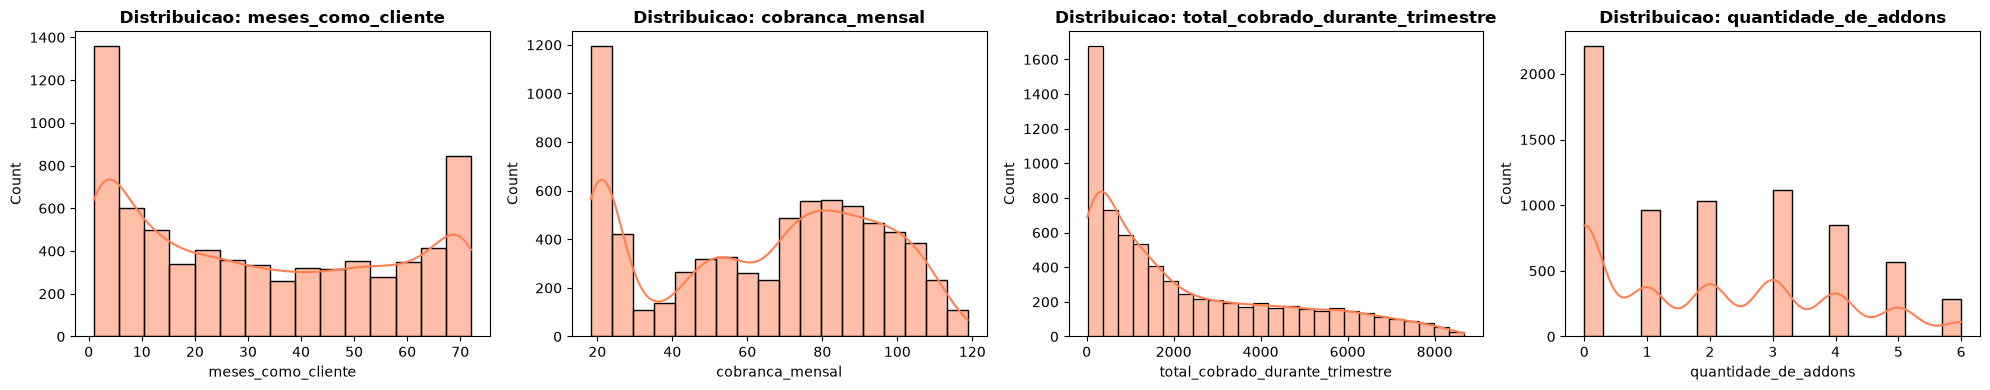

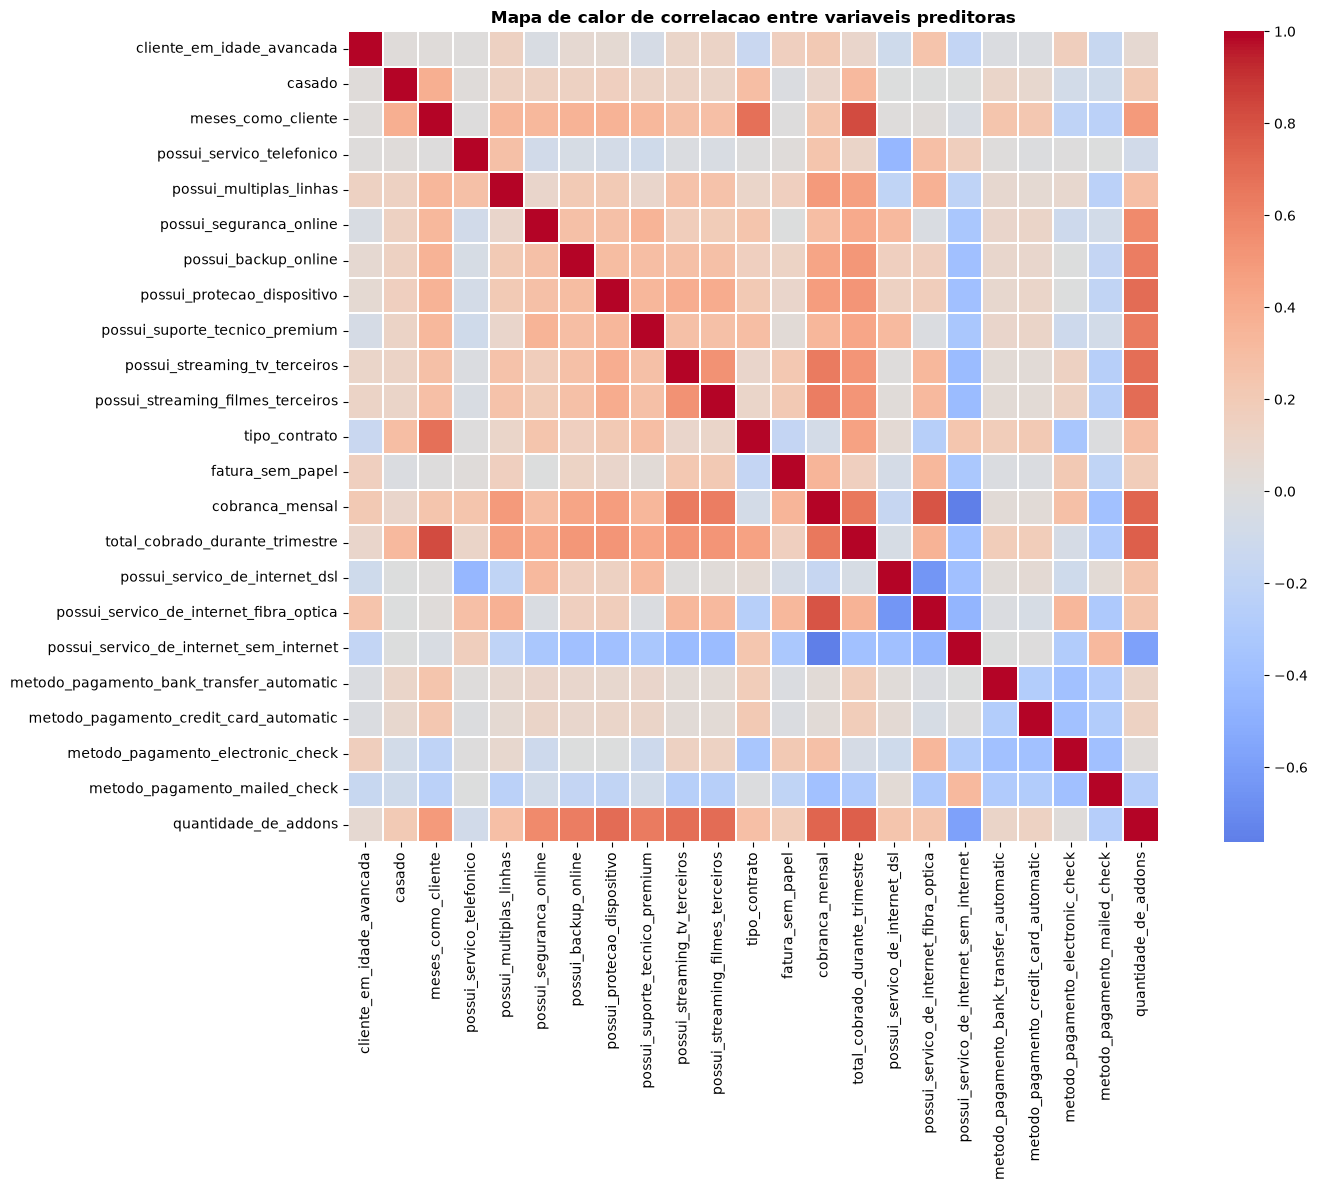

Pares de features preditoras com |correlacao| >= 0.5:
                              feature_1                               feature_2  correlacao
                     meses_como_cliente         total_cobrado_durante_trimestre       0.826
                        cobranca_mensal possui_servico_de_internet_fibra_optica       0.787
                        cobranca_mensal possui_servico_de_internet_sem_internet      -0.763
        total_cobrado_durante_trimestre                    quantidade_de_addons       0.746
                        cobranca_mensal                    quantidade_de_addons       0.725
            possui_protecao_dispositivo                    quantidade_de_addons       0.693
      possui_streaming_filmes_terceiros                    quantidade_de_addons       0.693
          possui_streaming_tv_terceiros                    quantidade_de_addons       0.688
                     meses_como_cliente                           tipo_contrato       0.677
                        co

In [11]:
colunas_numericas_para_distribuicao = ["meses_como_cliente", "cobranca_mensal", "total_cobrado_durante_trimestre", "quantidade_de_addons"]

fig, axes = plt.subplots(1, len(colunas_numericas_para_distribuicao), figsize=(20, 4))
for idx, col in enumerate(colunas_numericas_para_distribuicao):
    sns.histplot(dataframe_de_churn_missing_values_aplicado[col], kde=True, ax=axes[idx], color="coral")
    axes[idx].set_title(f"Distribuicao: {col}", fontweight="bold")

plt.tight_layout()
plt.show()

matriz_correlacao = dataframe_de_churn_missing_values_aplicado.drop(columns=["target"]).corr(numeric_only=True)

plt.figure(figsize=(16, 12))
sns.heatmap(matriz_correlacao, cmap="coolwarm", center=0, annot=False, square=True, linewidths=0.3)
plt.title("Mapa de calor de correlacao entre variaveis preditoras", fontweight="bold")
plt.tight_layout()
plt.show()

pares_colunas = matriz_correlacao.columns
pares_alta_correlacao = []
for i in range(len(pares_colunas)):
    for j in range(i + 1, len(pares_colunas)):
        valor_correlacao = matriz_correlacao.iloc[i, j]
        if abs(valor_correlacao) >= 0.5:
            pares_alta_correlacao.append((pares_colunas[i], pares_colunas[j], round(valor_correlacao, 3)))

tabela_alta_correlacao = pd.DataFrame(pares_alta_correlacao, columns=["feature_1", "feature_2", "correlacao"])
tabela_alta_correlacao = tabela_alta_correlacao.reindex(tabela_alta_correlacao["correlacao"].abs().sort_values(ascending=False).index)
print("Pares de features preditoras com |correlacao| >= 0.5:")
print(tabela_alta_correlacao.to_string(index=False))

print("\nCorrelacao de cada feature com o target:")
print(dataframe_de_churn_missing_values_aplicado.corr(numeric_only=True)["target"].sort_values(key=abs, ascending=False))

## Removendo feature redundante por alta colinearidade

In [ ]:
dataframe_de_churn_missing_values_aplicado = dataframe_de_churn_missing_values_aplicado.drop(
    columns=["total_cobrado_durante_trimestre"]
)

dataframe_de_churn_missing_values_aplicado.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check,quantidade_de_addons
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,0,1,0,0,0,0,1,0,1
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,0,1,0,0,0,0,0,1,2
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,1,1,0,0,0,0,0,1,2
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,0,1,0,0,1,0,0,0,3
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,1,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,1,0,1,0,0,0,1,0,1
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,0,1,0,0,0,1,0,0,3
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,1,0,0,1,0,0,0,1,0
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,0,0,0,1,1,0,0,0,0


## Proporcao da variavel target

=== DISTRIBUICAO DA VARIAVEL TARGET ===

Contagem:
target
0    5163
1    1869
Name: count, dtype: int64

Percentual:
Nao cancelou (0): 73.42%
Cancelou (1): 26.58%


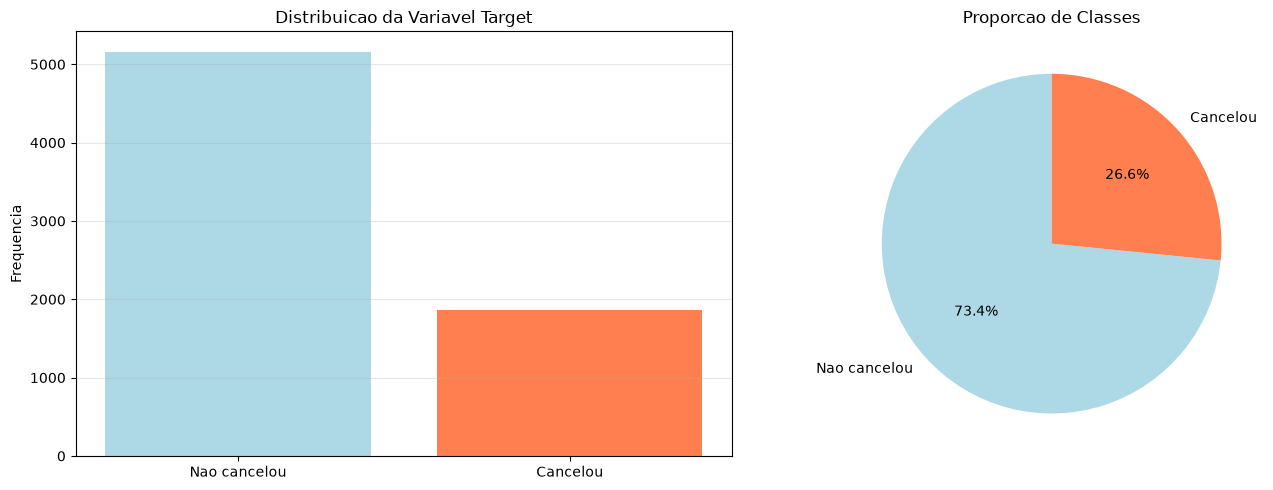


Ratio de balanceamento: 0.36
Dataset desbalanceado! Considere usar tecnicas como SMOTE ou class_weight.


In [13]:
print("=== DISTRIBUICAO DA VARIAVEL TARGET ===\n")
target_counts = dataframe_de_churn_missing_values_aplicado["target"].value_counts()
target_percentages = dataframe_de_churn_missing_values_aplicado["target"].value_counts(normalize=True) * 100

print("Contagem:")
print(target_counts)
print("\nPercentual:")
for idx, pct in target_percentages.items():
    label = "Nao cancelou" if idx == 0 else "Cancelou"
    print(f"{label} ({idx}): {pct:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(['Nao cancelou', 'Cancelou'], target_counts.values, color=['lightblue', 'coral'])
axes[0].set_ylabel('Frequencia')
axes[0].set_title('Distribuicao da Variavel Target')
axes[0].grid(axis='y', alpha=0.3)

axes[1].pie(target_counts.values, labels=['Nao cancelou', 'Cancelou'],
            autopct='%1.1f%%', colors=['lightblue', 'coral'], startangle=90)
axes[1].set_title('Proporcao de Classes')

plt.tight_layout()
plt.show()

ratio = target_counts.min() / target_counts.max()
print(f"\nRatio de balanceamento: {ratio:.2f}")
if ratio < 0.5:
    print("Dataset desbalanceado! Considere usar tecnicas como SMOTE ou class_weight.")
else:
    print("Dataset razoavelmente balanceado.")

## Analise de dispersao das variaveis numericas em relacao a media

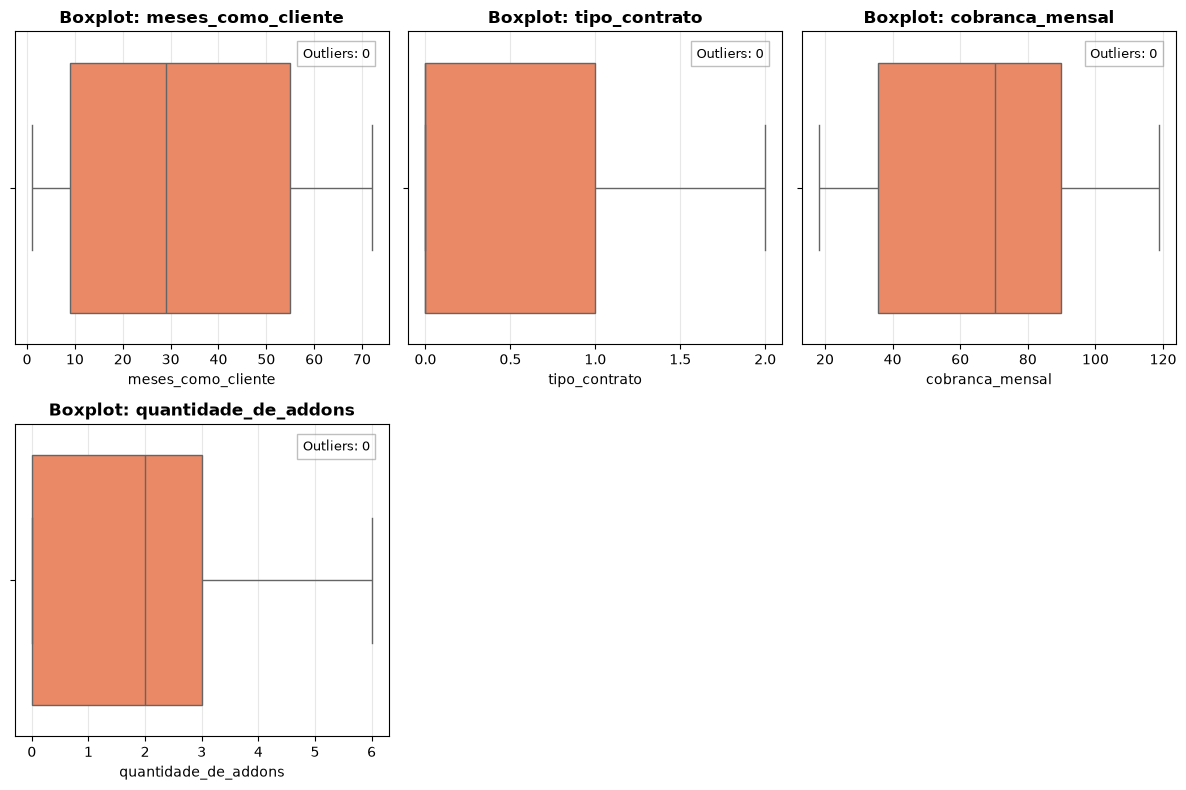

In [14]:
numeric_cols = ["meses_como_cliente", "tipo_contrato", "cobranca_mensal", "quantidade_de_addons"]

n = len(numeric_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
axes = axes.ravel()

for idx, col in enumerate(numeric_cols):
    sns.boxplot(x=dataframe_de_churn_missing_values_aplicado[col], ax=axes[idx], color='coral')
    axes[idx].set_title(f'Boxplot: {col}', fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].grid(axis='x', alpha=0.3)

    col_zscore = np.abs(stats.zscore(dataframe_de_churn_missing_values_aplicado[col].dropna()))
    outlier_count = (col_zscore > 3).sum()
    axes[idx].text(0.95, 0.95, f'Outliers: {outlier_count}',
                   transform=axes[idx].transAxes, fontsize=9,
                   verticalalignment='top', horizontalalignment='right',
                   bbox=dict(facecolor='white', alpha=0.5, edgecolor='gray'))

for ax in axes[n:]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

## Informacoes Estatisticas

In [15]:
colunas_para_describe = ["meses_como_cliente", "tipo_contrato", "cobranca_mensal", "quantidade_de_addons"]

dataframe_de_churn_missing_values_aplicado[colunas_para_describe].describe().round(2)

,meses_como_cliente,tipo_contrato,cobranca_mensal,quantidade_de_addons
count,7032.00,7032.00,7032.00,7032.00
mean,32.42,0.69,64.80,2.04
std,24.55,0.83,30.09,1.85
min,1.00,0.00,18.25,0.00
25%,9.00,0.00,35.59,0.00
50%,29.00,0.00,70.35,2.00
75%,55.00,1.00,89.86,3.00
max,72.00,2.00,118.75,6.00


## Dividindo dados entre treino e teste

In [16]:
X = dataframe_de_churn_missing_values_aplicado.drop(columns=["target"])
y = dataframe_de_churn_missing_values_aplicado["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}, y_train: {y_train.shape}, y_test: {y_test.shape}")

X_train: (4922, 22), X_test: (2110, 22), y_train: (4922,), y_test: (2110,)


## Redimensionando a escala dos dados antes do treino

In [17]:
colunas_para_escalonar = ["meses_como_cliente", "tipo_contrato", "cobranca_mensal", "quantidade_de_addons"]

escalonador = StandardScaler()

X_train_escalonado = X_train.copy()
X_test_escalonado = X_test.copy()

X_train_escalonado[colunas_para_escalonar] = escalonador.fit_transform(X_train[colunas_para_escalonar])
X_test_escalonado[colunas_para_escalonar] = escalonador.transform(X_test[colunas_para_escalonar])

X_train_escalonado.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check,quantidade_de_addons
4499,0,0,-0.833469,1,1,1,0,0,0,0,0,-0.830368,1,0.444749,0,1,0,0,0,1,0,-0.565455
1933,0,0,-0.508058,1,0,0,0,0,0,0,0,0.363635,1,-1.492135,0,0,1,0,0,0,1,-1.107139
4668,0,0,-1.240233,1,0,1,0,0,0,0,1,-0.830368,1,-0.120451,1,0,0,0,1,0,0,-0.023772
5681,1,1,0.061411,1,0,0,0,1,1,1,0,0.363635,0,-0.021293,1,0,0,1,0,0,0,0.517912
3610,0,0,-0.833469,1,1,0,0,1,0,1,1,-0.830368,1,1.166949,0,1,0,1,0,0,0,0.517912
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1750,0,0,0.712233,1,0,0,0,1,1,0,1,1.557638,1,0.821549,0,1,0,1,0,0,0,0.517912
1736,0,0,-1.280909,1,0,0,0,0,0,0,0,-0.830368,0,-1.498746,0,0,1,0,0,0,1,-1.107139
5350,0,1,0.834262,1,1,1,1,0,0,0,1,1.557638,0,0.160497,1,0,0,1,0,0,0,0.517912
219,0,0,-0.996174,1,0,0,0,0,0,1,0,-0.830368,1,0.500939,0,1,0,1,0,0,0,-0.565455


## Aplicando SMOTE para balanceamento entre as classes

In [18]:
smote = SMOTE(random_state=42)
X_train_balanceado, y_train_balanceado = smote.fit_resample(X_train_escalonado, y_train)

print("Distribuicao antes do SMOTE:")
print(y_train.value_counts())
print("\nDistribuicao depois do SMOTE:")
print(y_train_balanceado.value_counts())

Distribuicao antes do SMOTE:
target
0    3614
1    1308
Name: count, dtype: int64

Distribuicao depois do SMOTE:
target
1    3614
0    3614
Name: count, dtype: int64


## Treinamento do modelo com SMOTE e registro de metricas no DVC

Acuracia: 0.7664
Precisao: 0.5464
Recall: 0.7130
F1-score: 0.6187
ROC AUC: 0.8342
Matriz de confusao:
[[1217  332]
 [ 161  400]]


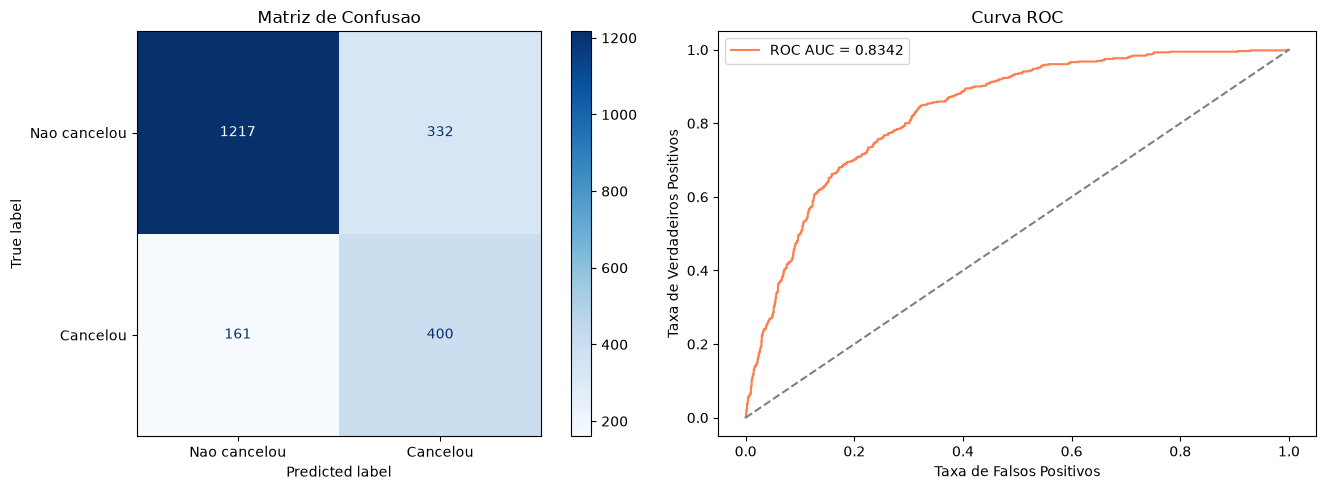

Path                                                          acuracia    f1_score    precisao    recall    roc_auc
notebooks\regressao_logistica\historico\metrics\metrics.json  0.76635     0.61872     0.54645     0.71301   0.83424




In [19]:
modelo_regressao_logistica = LogisticRegression(random_state=42, max_iter=1000)
modelo_regressao_logistica.fit(X_train_balanceado, y_train_balanceado)

y_pred = modelo_regressao_logistica.predict(X_test_escalonado)
y_proba = modelo_regressao_logistica.predict_proba(X_test_escalonado)[:, 1]

acuracia = accuracy_score(y_test, y_pred)
precisao = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
matriz_confusao = confusion_matrix(y_test, y_pred)
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

print(f"Acuracia: {acuracia:.4f}")
print(f"Precisao: {precisao:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")
print("Matriz de confusao:")
print(matriz_confusao)

metricas_dir = Path(r"C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\notebooks\regressao_logistica\historico\metrics")
metricas_dir.mkdir(parents=True, exist_ok=True)

metricas = {
    "acuracia": acuracia,
    "precisao": precisao,
    "recall": recall,
    "f1_score": f1,
    "roc_auc": roc_auc,
    "matriz_confusao": matriz_confusao.tolist(),
}

with open(metricas_dir / "metrics.json", "w") as arquivo_metricas:
    json.dump(metricas, arquivo_metricas, indent=4)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(confusion_matrix=matriz_confusao, display_labels=["Nao cancelou", "Cancelou"]).plot(ax=axes[0], cmap="Blues")
axes[0].set_title("Matriz de Confusao")

axes[1].plot(fpr, tpr, color="coral", label=f"ROC AUC = {roc_auc:.4f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("Taxa de Falsos Positivos")
axes[1].set_ylabel("Taxa de Verdadeiros Positivos")
axes[1].set_title("Curva ROC")
axes[1].legend()

plt.tight_layout()
plt.show()

resultado_dvc = subprocess.run(
    ["dvc", "metrics", "show"],
    cwd=r"C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction",
    capture_output=True, text=True
)
print(resultado_dvc.stdout)
print(resultado_dvc.stderr)